# 🧠 Twitter Bot Detection — Meta-Ensemble + Pseudo-Labeling Pipeline

This notebook implements a complete workflow combining **meta-ensembling** and **pseudo-labeling** for Twitter bot detection.

## Pipeline Overview

1. **Setup and Data Loading**
2. **Base Model Training** (XGBoost, LightGBM, CatBoost with Optuna-tuned params)
3. **Out-of-Fold (OOF) Predictions** for meta-model training
4. **Meta-Ensemble Layer** (Logistic Regression on OOF predictions)
5. **Pseudo-Labeling** (Confident test predictions → Extended training set)
6. **Final Predictions and Submission**

**Goal:** Maximize ROC-AUC through model diversity and semi-supervised learning.

## 🔧 Quick Configuration

**To force pseudo-labeling for Kaggle testing:**
1. Go to the **Configuration Options** cell below
2. Change `FORCE_PSEUDO_LABELING = False` to `FORCE_PSEUDO_LABELING = True`
3. Run all cells
4. Submit both generated CSV files to Kaggle to compare results!

**Default behavior (`False`):** Automatically selects best method based on CV performance  
**Testing mode (`True`):** Always uses pseudo-labeling + generates comparison file

## 1. Setup and Imports

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

# Add parent directory to path
current_dir = os.getcwd()
parent_dir = os.path.abspath(os.path.join(current_dir, '..'))
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

# Scikit-learn
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report, confusion_matrix

# Gradient boosting libraries
import xgboost as xgb
import lightgbm as lgb
import catboost as cb

# Optuna for hyperparameter tuning
import optuna
from optuna.samplers import TPESampler

# Custom preprocessing
from helpers.process_data import preprocess_data, in_fold_process_data

# Set random seeds for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# Plotting settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✅ All libraries imported successfully!")
print(f"Random state: {RANDOM_STATE}")
print(f"Working directory: {os.getcwd()}")

✅ All libraries imported successfully!
Random state: 42
Working directory: /Users/winston/Documents/School/Y3S1/BT4012/Kaggle/Competition 1/models


## Configuration Options

In [18]:
# =============================================================================
# CONFIGURATION FLAGS
# =============================================================================

# 🔧 FORCE PSEUDO-LABELING FOR KAGGLE TESTING
# Set to True to always use pseudo-labeling predictions in final submission
# Set to False to automatically select best method based on CV performance
FORCE_PSEUDO_LABELING = True # False  # Change to True to force pseudo-labeling

# Cross-validation folds
N_SPLITS = 5

# Pseudo-labeling confidence thresholds
HIGH_CONFIDENCE_THRESHOLD = 0.99  # Bot class (label = 1)
LOW_CONFIDENCE_THRESHOLD = 0.01   # Human class (label = 0)

print("="*70)
print("CONFIGURATION")
print("="*70)
print(f"\n🔧 Settings:")
print(f"  Force Pseudo-Labeling: {FORCE_PSEUDO_LABELING}")
print(f"  CV Folds: {N_SPLITS}")
print(f"  Pseudo-label Thresholds: >{HIGH_CONFIDENCE_THRESHOLD} (bot), <{LOW_CONFIDENCE_THRESHOLD} (human)")

if FORCE_PSEUDO_LABELING:
    print(f"\n⚠️  WARNING: Pseudo-labeling is FORCED for this run!")
    print(f"  The final submission will ALWAYS use pseudo-labeled predictions")
    print(f"  regardless of whether they improve CV performance.")
else:
    print(f"\n✅ Auto-selection mode: Best method chosen based on CV performance")

print("="*70)

CONFIGURATION

🔧 Settings:
  Force Pseudo-Labeling: True
  CV Folds: 5
  Pseudo-label Thresholds: >0.99 (bot), <0.01 (human)

⚠️  WARNING: Pseudo-labeling is FORCED for this run!
  The final submission will ALWAYS use pseudo-labeled predictions
  regardless of whether they improve CV performance.


## 2. Load and Prepare Data

In [2]:
# Load raw data
print("="*70)
print("LOADING DATA")
print("="*70)

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

# Separate features and target
y_train = train['target'].copy()
raw_train_features = train.drop('target', axis=1)

print(f"\n📊 Dataset Summary:")
print(f"  Training samples: {len(train):,}")
print(f"  Test samples: {len(test):,}")
print(f"  Features: {train.shape[1] - 1}")

print(f"\n🎯 Target Distribution:")
target_counts = y_train.value_counts().sort_index()
for label, count in target_counts.items():
    percentage = (count / len(y_train)) * 100
    emoji = "🤖" if label == 1 else "👤"
    print(f"  {emoji} Class {label}: {count:,} samples ({percentage:.1f}%)")

# Check for missing data
print(f"\n🔍 Missing Values in Training Data:")
missing_train = train.isnull().sum().sum()
print(f"  Total missing values: {missing_train:,}")

print(f"\n🔍 Missing Values in Test Data:")
missing_test = test.isnull().sum().sum()
print(f"  Total missing values: {missing_test:,}")

print("\n✅ Data loaded successfully!")

LOADING DATA

📊 Dataset Summary:
  Training samples: 26,206
  Test samples: 11,232
  Features: 18

🎯 Target Distribution:
  👤 Class 0: 17,423 samples (66.5%)
  🤖 Class 1: 8,783 samples (33.5%)

🔍 Missing Values in Training Data:
  Total missing values: 13,917

🔍 Missing Values in Test Data:
  Total missing values: 5,801

✅ Data loaded successfully!


## 3. Cross-Validation Setup

In [ ]:
# Setup stratified K-fold cross-validation
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# Pre-CV preprocessing (deterministic transformations only)
print("="*70)
print("PRE-CV PREPROCESSING")
print("="*70)

X_preprocessed = preprocess_data(raw_train_features, verbose=True, include_statuses_count=True)
X_test_preprocessed = preprocess_data(test, verbose=False, include_statuses_count=True)

print(f"\n✅ Preprocessed shapes:")
print(f"  Train: {X_preprocessed.shape}")
print(f"  Test: {X_test_preprocessed.shape}")

# Initialize storage for OOF predictions and test predictions
oof_predictions = {}
test_predictions = {}
cv_scores = {}

print(f"\n🔄 Cross-validation setup: {N_SPLITS}-fold StratifiedKFold")
print(f"  Random state: {RANDOM_STATE}")
print(f"  Shuffle: True")

PRE-CV PREPROCESSING
=== Pre-CV Data Preprocessing (No Leakage) ===
Original dataframe shape: (26206, 18)

Extracting numerical features...
  - favourites_count: extracted (missing: 0)
  - followers_count: extracted (missing: 0)
  - friends_count: extracted (missing: 0)
  - average_tweets_per_day: extracted (missing: 0)
  - account_age_days: extracted (missing: 0)
  - statuses_count: extracted (missing: 0)

Extracting binary features...
  - default_profile: extracted (missing: 0)
  - default_profile_image: extracted (missing: 0)
  - geo_enabled: extracted (missing: 0)
  - verified: extracted (missing: 0)

Extracting categorical features...
  - lang: extracted (49 categories)

Extracting textual features...
  - location_len: mean=11.05
  - description_len: mean=66.79
  - screen_name_len: mean=11.12
  - profile_background_image_url_len: mean=42.25
  - profile_image_url_len: mean=75.52
  - description_has_url: 3613 accounts (13.8%)
  - screen_name_has_numbers: 7015 accounts (26.8%)
  - lo

## 4. Base Model Training

We'll train three base models with Optuna-tuned hyperparameters:
1. **XGBoost** - Gradient boosting with tree-based learners
2. **LightGBM** - Fast gradient boosting framework
3. **CatBoost** - Gradient boosting with categorical feature support

### 4.1 XGBoost Model

In [4]:
# Load Optuna study to get best parameters
try:
    study_xgb = joblib.load('trained/optuna_study_xgb.joblib')
    xgb_params = study_xgb.best_params.copy()
    xgb_params.update({
        'random_state': RANDOM_STATE,
        'tree_method': 'hist',  # Use GPU if available: 'gpu_hist'
        'eval_metric': 'logloss'
    })
    print("✅ Loaded XGBoost Optuna parameters")
    print(f"  Best CV AUC: {study_xgb.best_value:.4f}")
except FileNotFoundError:
    print("⚠️ Optuna study not found, using default parameters")
    xgb_params = {
        'max_depth': 6,
        'learning_rate': 0.1,
        'n_estimators': 200,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
        'min_child_weight': 1,
        'gamma': 0,
        'random_state': RANDOM_STATE,
        'tree_method': 'hist',
        'eval_metric': 'logloss'
    }

print(f"\n📋 XGBoost Parameters:")
for key, val in xgb_params.items():
    print(f"  {key}: {val}")

✅ Loaded XGBoost Optuna parameters
  Best CV AUC: 0.9472

📋 XGBoost Parameters:
  n_estimators: 500
  max_depth: 8
  learning_rate: 0.02304364042504696
  subsample: 0.6105733875603306
  colsample_bytree: 0.8222008072142497
  min_child_weight: 5
  gamma: 0.1536483060584243
  reg_alpha: 0.47213769628665514
  reg_lambda: 0.7066301096506243
  random_state: 42
  tree_method: hist
  eval_metric: logloss


In [5]:
# Train XGBoost with 5-fold CV
print("\n" + "="*70)
print("TRAINING XGBOOST WITH 5-FOLD CV")
print("="*70)

oof_xgb = np.zeros(len(y_train))
test_xgb = np.zeros(len(test))
cv_scores_xgb = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_preprocessed, y_train), 1):
    print(f"\n{'='*20} FOLD {fold}/{N_SPLITS} {'='*20}")
    
    # Split data
    X_train_fold = X_preprocessed.iloc[train_idx]
    X_val_fold = X_preprocessed.iloc[val_idx]
    y_train_fold = y_train.iloc[train_idx]
    y_val_fold = y_train.iloc[val_idx]
    
    # In-fold processing (imputation & encoding)
    X_train_processed, X_val_processed, _ = in_fold_process_data(
        X_train_fold, X_val_fold,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=False
    )
    
    # Train XGBoost
    model = xgb.XGBClassifier(**xgb_params)
    model.fit(X_train_processed, y_train_fold, verbose=False)
    
    # Predict on validation fold
    val_pred = model.predict_proba(X_val_processed)[:, 1]
    oof_xgb[val_idx] = val_pred
    
    # Predict on test (will be averaged later)
    _, X_test_processed, _ = in_fold_process_data(
        X_train_processed.iloc[:100],
        X_test_preprocessed,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=False
    )
    
    # Align test features with training features
    if X_train_processed.shape[1] != X_test_processed.shape[1]:
        missing_cols = set(X_train_processed.columns) - set(X_test_processed.columns)
        extra_cols = set(X_test_processed.columns) - set(X_train_processed.columns)
        for col in missing_cols:
            X_test_processed[col] = 0
        for col in extra_cols:
            X_test_processed = X_test_processed.drop(columns=[col])
        X_test_processed = X_test_processed[X_train_processed.columns]
    
    test_pred = model.predict_proba(X_test_processed)[:, 1]
    test_xgb += test_pred / N_SPLITS
    
    # Calculate fold score
    fold_auc = roc_auc_score(y_val_fold, val_pred)
    cv_scores_xgb.append(fold_auc)
    
    print(f"  Fold {fold} AUC: {fold_auc:.4f}")

# Overall CV score
cv_auc_xgb = roc_auc_score(y_train, oof_xgb)
print(f"\n{'='*70}")
print(f"XGBoost Overall CV AUC: {cv_auc_xgb:.4f}")
print(f"Mean Fold AUC: {np.mean(cv_scores_xgb):.4f} (+/- {np.std(cv_scores_xgb):.4f})")
print(f"{'='*70}")

# Store results
oof_predictions['xgb'] = oof_xgb
test_predictions['xgb'] = test_xgb
cv_scores['xgb'] = cv_auc_xgb


TRAINING XGBOOST WITH 5-FOLD CV

==================== FOLD 1/5 ====================
  Fold 1 AUC: 0.9431

==================== FOLD 2/5 ====================
  Fold 1 AUC: 0.9431

==================== FOLD 2/5 ====================
  Fold 2 AUC: 0.9512

==================== FOLD 3/5 ====================
  Fold 2 AUC: 0.9512

==================== FOLD 3/5 ====================
  Fold 3 AUC: 0.9522

==================== FOLD 4/5 ====================
  Fold 3 AUC: 0.9522

==================== FOLD 4/5 ====================
  Fold 4 AUC: 0.9432

==================== FOLD 5/5 ====================
  Fold 4 AUC: 0.9432

==================== FOLD 5/5 ====================
  Fold 5 AUC: 0.9461

XGBoost Overall CV AUC: 0.9471
Mean Fold AUC: 0.9472 (+/- 0.0039)
  Fold 5 AUC: 0.9461

XGBoost Overall CV AUC: 0.9471
Mean Fold AUC: 0.9472 (+/- 0.0039)


### 4.2 LightGBM Model

In [6]:
# Load Optuna study to get best parameters
try:
    study_lgb = joblib.load('trained/optuna_study_lgb.joblib')
    lgb_params = study_lgb.best_params.copy()
    lgb_params.update({
        'random_state': RANDOM_STATE,
        'device': 'cpu',  # Use 'gpu' if available
        'verbose': -1
    })
    print("✅ Loaded LightGBM Optuna parameters")
    print(f"  Best CV AUC: {study_lgb.best_value:.4f}")
except FileNotFoundError:
    print("⚠️ Optuna study not found, using default parameters")
    lgb_params = {
        'max_depth': 6,
        'learning_rate': 0.1,
        'n_estimators': 200,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
        'min_child_samples': 20,
        'random_state': RANDOM_STATE,
        'device': 'cpu',
        'verbose': -1
    }

print(f"\n📋 LightGBM Parameters:")
for key, val in lgb_params.items():
    print(f"  {key}: {val}")

✅ Loaded LightGBM Optuna parameters
  Best CV AUC: 0.9464

📋 LightGBM Parameters:
  n_estimators: 300
  max_depth: 8
  learning_rate: 0.03452036021109606
  num_leaves: 55
  subsample: 0.7344425137826482
  colsample_bytree: 0.6915085646716037
  min_child_samples: 19
  reg_alpha: 0.7984377453462917
  reg_lambda: 0.4384174705954996
  random_state: 42
  device: cpu
  verbose: -1


In [7]:
# Train LightGBM with 5-fold CV
print("\n" + "="*70)
print("TRAINING LIGHTGBM WITH 5-FOLD CV")
print("="*70)

oof_lgb = np.zeros(len(y_train))
test_lgb = np.zeros(len(test))
cv_scores_lgb = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_preprocessed, y_train), 1):
    print(f"\n{'='*20} FOLD {fold}/{N_SPLITS} {'='*20}")
    
    # Split data
    X_train_fold = X_preprocessed.iloc[train_idx]
    X_val_fold = X_preprocessed.iloc[val_idx]
    y_train_fold = y_train.iloc[train_idx]
    y_val_fold = y_train.iloc[val_idx]
    
    # In-fold processing
    X_train_processed, X_val_processed, _ = in_fold_process_data(
        X_train_fold, X_val_fold,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=False
    )
    
    # Train LightGBM
    model = lgb.LGBMClassifier(**lgb_params)
    model.fit(X_train_processed, y_train_fold)
    
    # Predict on validation fold
    val_pred = model.predict_proba(X_val_processed)[:, 1]
    oof_lgb[val_idx] = val_pred
    
    # Process and predict on test
    _, X_test_processed, _ = in_fold_process_data(
        X_train_processed.iloc[:100],
        X_test_preprocessed,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=False
    )
    
    # Align features
    if X_train_processed.shape[1] != X_test_processed.shape[1]:
        missing_cols = set(X_train_processed.columns) - set(X_test_processed.columns)
        extra_cols = set(X_test_processed.columns) - set(X_train_processed.columns)
        for col in missing_cols:
            X_test_processed[col] = 0
        for col in extra_cols:
            X_test_processed = X_test_processed.drop(columns=[col])
        X_test_processed = X_test_processed[X_train_processed.columns]
    
    test_pred = model.predict_proba(X_test_processed)[:, 1]
    test_lgb += test_pred / N_SPLITS
    
    # Calculate fold score
    fold_auc = roc_auc_score(y_val_fold, val_pred)
    cv_scores_lgb.append(fold_auc)
    
    print(f"  Fold {fold} AUC: {fold_auc:.4f}")

# Overall CV score
cv_auc_lgb = roc_auc_score(y_train, oof_lgb)
print(f"\n{'='*70}")
print(f"LightGBM Overall CV AUC: {cv_auc_lgb:.4f}")
print(f"Mean Fold AUC: {np.mean(cv_scores_lgb):.4f} (+/- {np.std(cv_scores_lgb):.4f})")
print(f"{'='*70}")

# Store results
oof_predictions['lgb'] = oof_lgb
test_predictions['lgb'] = test_lgb
cv_scores['lgb'] = cv_auc_lgb


TRAINING LIGHTGBM WITH 5-FOLD CV

==================== FOLD 1/5 ====================
  Fold 1 AUC: 0.9420

==================== FOLD 2/5 ====================
  Fold 1 AUC: 0.9420

==================== FOLD 2/5 ====================
  Fold 2 AUC: 0.9506

==================== FOLD 3/5 ====================
  Fold 2 AUC: 0.9506

==================== FOLD 3/5 ====================
  Fold 3 AUC: 0.9513

==================== FOLD 4/5 ====================
  Fold 3 AUC: 0.9513

==================== FOLD 4/5 ====================
  Fold 4 AUC: 0.9428

==================== FOLD 5/5 ====================
  Fold 4 AUC: 0.9428

==================== FOLD 5/5 ====================
  Fold 5 AUC: 0.9454

LightGBM Overall CV AUC: 0.9463
Mean Fold AUC: 0.9464 (+/- 0.0039)
  Fold 5 AUC: 0.9454

LightGBM Overall CV AUC: 0.9463
Mean Fold AUC: 0.9464 (+/- 0.0039)


### 4.3 CatBoost Model

In [8]:
# Load Optuna study to get best parameters
try:
    study_cat = joblib.load('trained/optuna_study_catboost.joblib')
    cat_params = study_cat.best_params.copy()
    cat_params.update({
        'random_state': RANDOM_STATE,
        'task_type': 'CPU',  # Use 'GPU' if available
        'verbose': False
    })
    print("✅ Loaded CatBoost Optuna parameters")
    print(f"  Best CV AUC: {study_cat.best_value:.4f}")
except FileNotFoundError:
    print("⚠️ Optuna study not found, using default parameters")
    cat_params = {
        'iterations': 200,
        'depth': 6,
        'learning_rate': 0.1,
        'subsample': 0.8,
        'colsample_bylevel': 0.8,
        'random_state': RANDOM_STATE,
        'task_type': 'CPU',
        'verbose': False
    }

print(f"\n📋 CatBoost Parameters:")
for key, val in cat_params.items():
    print(f"  {key}: {val}")

✅ Loaded CatBoost Optuna parameters
  Best CV AUC: 0.9454

📋 CatBoost Parameters:
  iterations: 450
  depth: 9
  learning_rate: 0.037571221131462336
  subsample: 0.9576712531883704
  colsample_bylevel: 0.8219639545008898
  min_data_in_leaf: 30
  l2_leaf_reg: 8.529254712965379
  random_state: 42
  task_type: CPU
  verbose: False


In [9]:
# Train CatBoost with 5-fold CV
print("\n" + "="*70)
print("TRAINING CATBOOST WITH 5-FOLD CV")
print("="*70)

oof_cat = np.zeros(len(y_train))
test_cat = np.zeros(len(test))
cv_scores_cat = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_preprocessed, y_train), 1):
    print(f"\n{'='*20} FOLD {fold}/{N_SPLITS} {'='*20}")
    
    # Split data
    X_train_fold = X_preprocessed.iloc[train_idx]
    X_val_fold = X_preprocessed.iloc[val_idx]
    y_train_fold = y_train.iloc[train_idx]
    y_val_fold = y_train.iloc[val_idx]
    
    # In-fold processing
    X_train_processed, X_val_processed, _ = in_fold_process_data(
        X_train_fold, X_val_fold,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=False
    )
    
    # Train CatBoost
    model = cb.CatBoostClassifier(**cat_params)
    model.fit(X_train_processed, y_train_fold)
    
    # Predict on validation fold
    val_pred = model.predict_proba(X_val_processed)[:, 1]
    oof_cat[val_idx] = val_pred
    
    # Process and predict on test
    _, X_test_processed, _ = in_fold_process_data(
        X_train_processed.iloc[:100],
        X_test_preprocessed,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=False
    )
    
    # Align features
    if X_train_processed.shape[1] != X_test_processed.shape[1]:
        missing_cols = set(X_train_processed.columns) - set(X_test_processed.columns)
        extra_cols = set(X_test_processed.columns) - set(X_train_processed.columns)
        for col in missing_cols:
            X_test_processed[col] = 0
        for col in extra_cols:
            X_test_processed = X_test_processed.drop(columns=[col])
        X_test_processed = X_test_processed[X_train_processed.columns]
    
    test_pred = model.predict_proba(X_test_processed)[:, 1]
    test_cat += test_pred / N_SPLITS
    
    # Calculate fold score
    fold_auc = roc_auc_score(y_val_fold, val_pred)
    cv_scores_cat.append(fold_auc)
    
    print(f"  Fold {fold} AUC: {fold_auc:.4f}")

# Overall CV score
cv_auc_cat = roc_auc_score(y_train, oof_cat)
print(f"\n{'='*70}")
print(f"CatBoost Overall CV AUC: {cv_auc_cat:.4f}")
print(f"Mean Fold AUC: {np.mean(cv_scores_cat):.4f} (+/- {np.std(cv_scores_cat):.4f})")
print(f"{'='*70}")

# Store results
oof_predictions['cat'] = oof_cat
test_predictions['cat'] = test_cat
cv_scores['cat'] = cv_auc_cat


TRAINING CATBOOST WITH 5-FOLD CV

==================== FOLD 1/5 ====================
  Fold 1 AUC: 0.9417

==================== FOLD 2/5 ====================
  Fold 1 AUC: 0.9417

==================== FOLD 2/5 ====================
  Fold 2 AUC: 0.9495

==================== FOLD 3/5 ====================
  Fold 2 AUC: 0.9495

==================== FOLD 3/5 ====================
  Fold 3 AUC: 0.9493

==================== FOLD 4/5 ====================
  Fold 3 AUC: 0.9493

==================== FOLD 4/5 ====================
  Fold 4 AUC: 0.9414

==================== FOLD 5/5 ====================
  Fold 4 AUC: 0.9414

==================== FOLD 5/5 ====================
  Fold 5 AUC: 0.9453

CatBoost Overall CV AUC: 0.9454
Mean Fold AUC: 0.9454 (+/- 0.0035)
  Fold 5 AUC: 0.9453

CatBoost Overall CV AUC: 0.9454
Mean Fold AUC: 0.9454 (+/- 0.0035)


### 4.4 Base Model Performance Summary

In [10]:
# Summary of base model performance
print("\n" + "="*70)
print("BASE MODEL PERFORMANCE SUMMARY")
print("="*70)

results_df = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM', 'CatBoost'],
    'CV AUC': [cv_scores['xgb'], cv_scores['lgb'], cv_scores['cat']]
}).sort_values('CV AUC', ascending=False)

print("\n📊 Cross-Validation Results:")
print(results_df.to_string(index=False))

best_model = results_df.iloc[0]['Model']
best_auc = results_df.iloc[0]['CV AUC']
print(f"\n🏆 Best Base Model: {best_model} (AUC: {best_auc:.4f})")

# Save OOF predictions
os.makedirs('oof_predictions', exist_ok=True)
for model_name, preds in oof_predictions.items():
    joblib.dump(preds, f'oof_predictions/oof_{model_name}.pkl')
print(f"\n✅ Saved OOF predictions to 'oof_predictions/' directory")


BASE MODEL PERFORMANCE SUMMARY

📊 Cross-Validation Results:
   Model  CV AUC
 XGBoost  0.9471
LightGBM  0.9463
CatBoost  0.9454

🏆 Best Base Model: XGBoost (AUC: 0.9471)

✅ Saved OOF predictions to 'oof_predictions/' directory


## 5. Meta-Ensemble Layer

We'll use the OOF predictions from all base models as features to train a meta-model (Logistic Regression).

META-ENSEMBLE TRAINING

📊 Meta-feature shapes:
  Train: (26206, 3)
  Test: (11232, 3)

🔍 Meta-feature correlation:
          xgb_pred  lgb_pred  cat_pred
xgb_pred    1.0000    0.9943    0.9900
lgb_pred    0.9943    1.0000    0.9895
cat_pred    0.9900    0.9895    1.0000


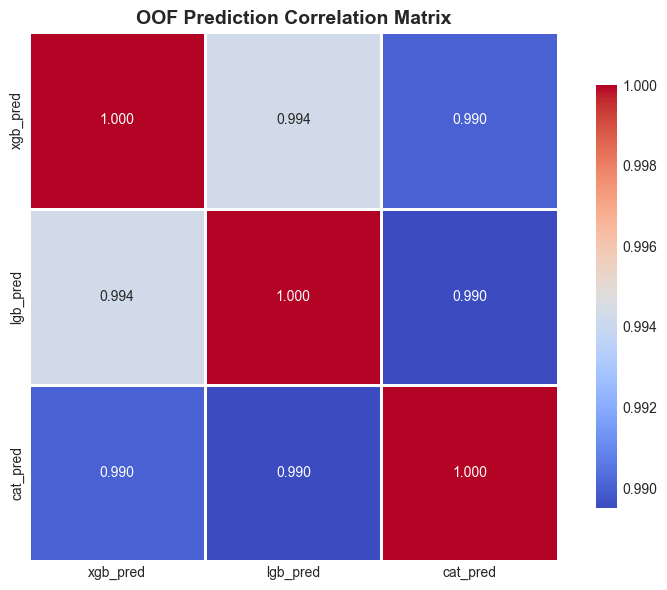


💡 Lower correlation = higher model diversity = better ensemble!


In [11]:
# Create meta-features from OOF predictions
print("="*70)
print("META-ENSEMBLE TRAINING")
print("="*70)

# Stack OOF predictions as meta-features
meta_train = pd.DataFrame({
    'xgb_pred': oof_predictions['xgb'],
    'lgb_pred': oof_predictions['lgb'],
    'cat_pred': oof_predictions['cat']
})

# Stack test predictions as meta-features
meta_test = pd.DataFrame({
    'xgb_pred': test_predictions['xgb'],
    'lgb_pred': test_predictions['lgb'],
    'cat_pred': test_predictions['cat']
})

print(f"\n📊 Meta-feature shapes:")
print(f"  Train: {meta_train.shape}")
print(f"  Test: {meta_test.shape}")

print(f"\n🔍 Meta-feature correlation:")
print(meta_train.corr())

# Visualize correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(meta_train.corr(), annot=True, fmt='.3f', cmap='coolwarm', 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('OOF Prediction Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n💡 Lower correlation = higher model diversity = better ensemble!")

In [ ]:
# Compare multiple meta-models
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier

print("\n" + "="*70)
print("COMPARING MULTIPLE META-MODELS")
print("="*70)

# Define meta-models to compare
meta_models = {
    'Logistic Regression': LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=RANDOM_STATE,
        solver='lbfgs'
    ),
    'Ridge': Ridge(
        alpha=1.0,
        random_state=RANDOM_STATE
    ),
    'XGBoost Meta': xgb.XGBClassifier(
        max_depth=2,
        learning_rate=0.1,
        n_estimators=50,
        random_state=RANDOM_STATE,
        tree_method='hist',
        eval_metric='logloss'
    ),
    'LightGBM Meta': lgb.LGBMClassifier(
        max_depth=2,
        learning_rate=0.1,
        n_estimators=50,
        random_state=RANDOM_STATE,
        device='cpu',
        verbose=-1
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        max_depth=3,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    'Neural Network': MLPClassifier(
        hidden_layer_sizes=(10, 5),
        max_iter=1000,
        random_state=RANDOM_STATE,
        early_stopping=True
    )
}

print(f"\n🔬 Testing {len(meta_models)} different meta-models...")
print(f"  Meta-features: {list(meta_train.columns)}")

# Train and evaluate each meta-model
meta_results = {}
meta_predictions_train = {}
meta_predictions_test = {}

for name, model in meta_models.items():
    print(f"\n  Training {name}...", end=" ")
    
    # Train meta-model
    model.fit(meta_train, y_train)
    
    # Generate predictions
    if hasattr(model, 'predict_proba'):
        train_pred = model.predict_proba(meta_train)[:, 1]
        test_pred = model.predict_proba(meta_test)[:, 1]
    else:
        # For models without predict_proba (like Ridge)
        train_pred = model.predict(meta_train)
        test_pred = model.predict(meta_test)
        # Clip to [0, 1] range
        train_pred = np.clip(train_pred, 0, 1)
        test_pred = np.clip(test_pred, 0, 1)
    
    # Evaluate
    auc = roc_auc_score(y_train, train_pred)
    acc = accuracy_score(y_train, (train_pred > 0.5).astype(int))
    
    # Store results
    meta_results[name] = {
        'AUC': auc,
        'Accuracy': acc,
        'model': model
    }
    meta_predictions_train[name] = train_pred
    meta_predictions_test[name] = test_pred
    
    print(f"AUC: {auc:.4f}, Acc: {acc:.4f}")

# Display results
print(f"\n{'='*70}")
print("META-MODEL COMPARISON RESULTS")
print(f"{'='*70}")

results_df = pd.DataFrame({
    'Meta-Model': list(meta_results.keys()),
    'Training AUC': [meta_results[m]['AUC'] for m in meta_results],
    'Training Accuracy': [meta_results[m]['Accuracy'] for m in meta_results]
}).sort_values('Training AUC', ascending=False)

print("\n📊 Performance Summary:")
print(results_df.to_string(index=False))

# Select best meta-model
best_meta_name = results_df.iloc[0]['Meta-Model']
best_meta_auc = results_df.iloc[0]['Training AUC']
meta_model = meta_results[best_meta_name]['model']
meta_train_pred = meta_predictions_train[best_meta_name]
meta_test_pred = meta_predictions_test[best_meta_name]
meta_auc = best_meta_auc

print(f"\n🏆 Best Meta-Model: {best_meta_name}")
print(f"  Training AUC: {best_meta_auc:.4f}")

# Show feature importance/coefficients for best model
print(f"\n⚖️ {best_meta_name} Feature Importance:")
if hasattr(meta_model, 'coef_'):
    # Linear models
    coef_df = pd.DataFrame({
        'Model': meta_train.columns,
        'Coefficient': meta_model.coef_[0] if meta_model.coef_.ndim > 1 else meta_model.coef_
    }).sort_values('Coefficient', ascending=False)
    print(coef_df.to_string(index=False))
elif hasattr(meta_model, 'feature_importances_'):
    # Tree-based models
    importance_df = pd.DataFrame({
        'Model': meta_train.columns,
        'Importance': meta_model.feature_importances_
    }).sort_values('Importance', ascending=False)
    print(importance_df.to_string(index=False))
else:
    print("  (Feature importance not available for this model type)")

# Compare best meta-model with base models
print(f"\n📊 Performance Comparison:")
comparison_df = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM', 'CatBoost', f'🌟 {best_meta_name}'],
    'CV AUC': [cv_scores['xgb'], cv_scores['lgb'], cv_scores['cat'], best_meta_auc]
}).sort_values('CV AUC', ascending=False)
print(comparison_df.to_string(index=False))

improvement = best_meta_auc - max(cv_scores.values())
print(f"\n🚀 Improvement over best base model: {improvement:+.4f}")

# Save best meta-model
os.makedirs('trained', exist_ok=True)
joblib.dump(meta_model, 'trained/meta_model_best.joblib')
joblib.dump(meta_results, 'trained/meta_model_comparison.joblib')
print(f"\n✅ Saved best meta-model ({best_meta_name}) to 'trained/meta_model_best.joblib'")
print(f"✅ Saved all meta-model results to 'trained/meta_model_comparison.joblib'")


TRAINING META-MODEL (LOGISTIC REGRESSION)

📈 Meta-Model Performance:
  Training AUC: 0.9474
  Training Accuracy: 0.8904

⚖️ Meta-Model Coefficients:
   Model  Coefficient
cat_pred       2.6187
xgb_pred       2.1370
lgb_pred       1.8504

💡 Higher coefficient = more weight in ensemble

📊 Performance Comparison:
          Model  CV AUC
🌟 Meta-Ensemble  0.9474
        XGBoost  0.9471
       LightGBM  0.9463
       CatBoost  0.9454

🚀 Improvement over best base model: +0.0003

✅ Saved meta-model to 'trained/meta_model.joblib'

📈 Meta-Model Performance:
  Training AUC: 0.9474
  Training Accuracy: 0.8904

⚖️ Meta-Model Coefficients:
   Model  Coefficient
cat_pred       2.6187
xgb_pred       2.1370
lgb_pred       1.8504

💡 Higher coefficient = more weight in ensemble

📊 Performance Comparison:
          Model  CV AUC
🌟 Meta-Ensemble  0.9474
        XGBoost  0.9471
       LightGBM  0.9463
       CatBoost  0.9454

🚀 Improvement over best base model: +0.0003

✅ Saved meta-model to 'trained/meta

In [ ]:
# Visualize meta-model comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Meta-model AUC comparison
ax1 = axes[0]
meta_names = results_df['Meta-Model'].values
meta_aucs = results_df['Training AUC'].values
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(meta_names)))

bars = ax1.barh(meta_names, meta_aucs, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax1.set_xlabel('Training AUC', fontsize=12, fontweight='bold')
ax1.set_title('Meta-Model Performance Comparison', fontsize=14, fontweight='bold')
ax1.set_xlim(min(meta_aucs) - 0.001, max(meta_aucs) + 0.001)
ax1.grid(axis='x', alpha=0.3, linestyle='--')

# Highlight best model
best_idx = 0
bars[best_idx].set_edgecolor('gold')
bars[best_idx].set_linewidth(3)

# Add value labels
for i, (name, auc) in enumerate(zip(meta_names, meta_aucs)):
    label = f'{auc:.4f}'
    if i == best_idx:
        label = f'{auc:.4f} ⭐'
    ax1.text(auc + 0.0001, i, label, va='center', fontsize=10, fontweight='bold')

# Plot 2: Meta-model prediction distribution comparison
ax2 = axes[1]
for name in list(meta_predictions_train.keys())[:4]:  # Show top 4 to avoid clutter
    ax2.hist(meta_predictions_train[name], bins=30, alpha=0.4, label=name)

ax2.set_xlabel('Predicted Probability', fontsize=12, fontweight='bold')
ax2.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax2.set_title('Meta-Model Prediction Distributions (OOF)', fontsize=14, fontweight='bold')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

print(f"\n💡 The best meta-model ({best_meta_name}) will be used for final predictions!")

## 6. Pseudo-Labeling

Use confident test predictions to augment the training set and retrain the best base model.

In [19]:
# Select confident predictions from test set
print("="*70)
print("PSEUDO-LABELING")
print("="*70)

# Use confidence thresholds from configuration
print(f"\n🎯 Confidence Thresholds (from config):")
print(f"  Bot (label=1): probability > {HIGH_CONFIDENCE_THRESHOLD}")
print(f"  Human (label=0): probability < {LOW_CONFIDENCE_THRESHOLD}")

# Use meta-model predictions for pseudo-labeling
confident_bot_mask = meta_test_pred > HIGH_CONFIDENCE_THRESHOLD
confident_human_mask = meta_test_pred < LOW_CONFIDENCE_THRESHOLD

n_confident_bots = confident_bot_mask.sum()
n_confident_humans = confident_human_mask.sum()
n_confident_total = n_confident_bots + n_confident_humans

print(f"\n🎯 Confidence Thresholds:")
print(f"  Bot (label=1): probability > {HIGH_CONFIDENCE_THRESHOLD}")
print(f"  Human (label=0): probability < {LOW_CONFIDENCE_THRESHOLD}")

print(f"\n📊 Confident Predictions:")
print(f"  🤖 Confident bots: {n_confident_bots:,} ({n_confident_bots/len(test)*100:.1f}%)")
print(f"  👤 Confident humans: {n_confident_humans:,} ({n_confident_humans/len(test)*100:.1f}%)")
print(f"  Total confident: {n_confident_total:,} ({n_confident_total/len(test)*100:.1f}%)")

# Create pseudo-labels
pseudo_labels = np.zeros(len(test))
pseudo_labels[confident_bot_mask] = 1
pseudo_labels[confident_human_mask] = 0

# Get confident test samples
confident_mask = confident_bot_mask | confident_human_mask
X_pseudo = X_test_preprocessed[confident_mask].copy()
y_pseudo = pseudo_labels[confident_mask]

print(f"\n📦 Pseudo-labeled dataset:")
print(f"  Size: {len(X_pseudo):,} samples")
print(f"  Bot samples: {(y_pseudo == 1).sum():,}")
print(f"  Human samples: {(y_pseudo == 0).sum():,}")

# Combine original training data with pseudo-labeled data
X_extended = pd.concat([X_preprocessed, X_pseudo], axis=0, ignore_index=True)
y_extended = pd.concat([y_train, pd.Series(y_pseudo)], axis=0, ignore_index=True)

print(f"\n📈 Extended training set:")
print(f"  Original: {len(X_preprocessed):,} samples")
print(f"  Pseudo-labeled: {len(X_pseudo):,} samples")
print(f"  Extended: {len(X_extended):,} samples (+{len(X_pseudo)/len(X_preprocessed)*100:.1f}%)")

PSEUDO-LABELING

🎯 Confidence Thresholds (from config):
  Bot (label=1): probability > 0.99
  Human (label=0): probability < 0.01

🎯 Confidence Thresholds:
  Bot (label=1): probability > 0.99
  Human (label=0): probability < 0.01

📊 Confident Predictions:
  🤖 Confident bots: 0 (0.0%)
  👤 Confident humans: 0 (0.0%)
  Total confident: 0 (0.0%)

📦 Pseudo-labeled dataset:
  Size: 0 samples
  Bot samples: 0
  Human samples: 0

📈 Extended training set:
  Original: 26,206 samples
  Pseudo-labeled: 0 samples
  Extended: 26,206 samples (+0.0%)


In [20]:
# Retrain best base model on extended dataset
print("\n" + "="*70)
print("RETRAINING WITH PSEUDO-LABELS")
print("="*70)

# Determine best base model
best_model_name = max(cv_scores, key=cv_scores.get)
print(f"\n🏆 Best base model: {best_model_name.upper()} (CV AUC: {cv_scores[best_model_name]:.4f})")

# Select parameters based on best model
if best_model_name == 'xgb':
    retrain_params = xgb_params
    ModelClass = xgb.XGBClassifier
elif best_model_name == 'lgb':
    retrain_params = lgb_params
    ModelClass = lgb.LGBMClassifier
else:  # cat
    retrain_params = cat_params
    ModelClass = cb.CatBoostClassifier

# Train on extended dataset with 5-fold CV
print(f"\n🔄 Cross-validating on extended dataset...")

oof_extended = np.zeros(len(y_extended))
test_extended = np.zeros(len(test))
cv_scores_extended = []

skf_extended = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

for fold, (train_idx, val_idx) in enumerate(skf_extended.split(X_extended, y_extended), 1):
    print(f"\n  Fold {fold}/{N_SPLITS}...", end=" ")
    
    # Split data
    X_train_fold = X_extended.iloc[train_idx]
    X_val_fold = X_extended.iloc[val_idx]
    y_train_fold = y_extended.iloc[train_idx]
    y_val_fold = y_extended.iloc[val_idx]
    
    # In-fold processing
    X_train_processed, X_val_processed, _ = in_fold_process_data(
        X_train_fold, X_val_fold,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=False
    )
    
    # Train model
    model = ModelClass(**retrain_params)
    model.fit(X_train_processed, y_train_fold)
    
    # Predict on validation fold
    val_pred = model.predict_proba(X_val_processed)[:, 1]
    oof_extended[val_idx] = val_pred
    
    # Process and predict on test
    _, X_test_processed, _ = in_fold_process_data(
        X_train_processed.iloc[:100],
        X_test_preprocessed,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=False
    )
    
    # Align features
    if X_train_processed.shape[1] != X_test_processed.shape[1]:
        missing_cols = set(X_train_processed.columns) - set(X_test_processed.columns)
        extra_cols = set(X_test_processed.columns) - set(X_train_processed.columns)
        for col in missing_cols:
            X_test_processed[col] = 0
        for col in extra_cols:
            X_test_processed = X_test_processed.drop(columns=[col])
        X_test_processed = X_test_processed[X_train_processed.columns]
    
    test_pred = model.predict_proba(X_test_processed)[:, 1]
    test_extended += test_pred / N_SPLITS
    
    # Calculate fold score
    fold_auc = roc_auc_score(y_val_fold, val_pred)
    cv_scores_extended.append(fold_auc)
    
    print(f"AUC: {fold_auc:.4f}")

# Overall CV score
cv_auc_extended = roc_auc_score(y_extended, oof_extended)

print(f"\n{'='*70}")
print(f"PSEUDO-LABELING RESULTS")
print(f"{'='*70}")
print(f"\n📊 Performance Comparison:")
print(f"  Original {best_model_name.upper()} CV AUC: {cv_scores[best_model_name]:.4f}")
print(f"  With Pseudo-labels CV AUC: {cv_auc_extended:.4f}")
improvement_pseudo = cv_auc_extended - cv_scores[best_model_name]
print(f"  Improvement: {improvement_pseudo:+.4f}")

if improvement_pseudo > 0:
    print(f"\n✅ Pseudo-labeling improved performance!")
else:
    print(f"\n⚠️ Pseudo-labeling did not improve performance. Using meta-ensemble instead.")


RETRAINING WITH PSEUDO-LABELS

🏆 Best base model: XGB (CV AUC: 0.9471)

🔄 Cross-validating on extended dataset...

  Fold 1/5... AUC: 0.9431

  Fold 2/5... AUC: 0.9431

  Fold 2/5... AUC: 0.9512

  Fold 3/5... AUC: 0.9512

  Fold 3/5... AUC: 0.9522

  Fold 4/5... AUC: 0.9522

  Fold 4/5... AUC: 0.9432

  Fold 5/5... AUC: 0.9432

  Fold 5/5... AUC: 0.9461

PSEUDO-LABELING RESULTS

📊 Performance Comparison:
  Original XGB CV AUC: 0.9471
  With Pseudo-labels CV AUC: 0.9471
  Improvement: +0.0000

⚠️ Pseudo-labeling did not improve performance. Using meta-ensemble instead.
AUC: 0.9461

PSEUDO-LABELING RESULTS

📊 Performance Comparison:
  Original XGB CV AUC: 0.9471
  With Pseudo-labels CV AUC: 0.9471
  Improvement: +0.0000

⚠️ Pseudo-labeling did not improve performance. Using meta-ensemble instead.


## 7. Final Predictions and Submission

In [21]:
# Select best predictions for final submission
print("="*70)
print("FINAL SUBMISSION")
print("="*70)

# Compare all approaches
final_options = {
    'Meta-Ensemble': (meta_test_pred, meta_auc),
    f'{best_model_name.upper()} + Pseudo-labels': (test_extended, cv_auc_extended),
    f'Best Base Model ({best_model_name.upper()})': (test_predictions[best_model_name], cv_scores[best_model_name])
}

print(f"\n📊 Final Model Options:")
for name, (_, auc) in sorted(final_options.items(), key=lambda x: x[1][1], reverse=True):
    print(f"  {name}: CV AUC = {auc:.4f}")

# Choose best approach based on configuration
if FORCE_PSEUDO_LABELING:
    # Force pseudo-labeling regardless of performance
    final_predictions = test_extended
    final_method = f'{best_model_name.upper()} + Pseudo-labels (FORCED)'
    final_auc = cv_auc_extended
    print(f"\n🔧 FORCED MODE: Using pseudo-labeling for testing")
    print(f"  (Change FORCE_PSEUDO_LABELING to False for automatic selection)")
elif improvement_pseudo > 0 and cv_auc_extended > meta_auc:
    # Pseudo-labeling improved performance
    final_predictions = test_extended
    final_method = f'{best_model_name.upper()} + Pseudo-labels'
    final_auc = cv_auc_extended
else:
    # Meta-ensemble performs better
    final_predictions = meta_test_pred
    final_method = 'Meta-Ensemble'
    final_auc = meta_auc

print(f"\n🏆 Selected Method: {final_method}")
print(f"  Expected AUC: {final_auc:.4f}")

if FORCE_PSEUDO_LABELING:
    print(f"\n⚠️  Note: Pseudo-labeling was forced. Meta-ensemble AUC was {meta_auc:.4f}")

# Create submission file
submission = pd.DataFrame({
    'index': test['index'],
    'target': final_predictions
})

# Save submission
os.makedirs('../submissions', exist_ok=True)
if FORCE_PSEUDO_LABELING:
    submission_path = '../submissions/meta_ensemble_pseudo_forced.csv'
else:
    submission_path = '../submissions/meta_ensemble.csv'
submission.to_csv(submission_path, index=False)

# Also save both versions for comparison if forcing pseudo-labeling
if FORCE_PSEUDO_LABELING:
    meta_submission = pd.DataFrame({
        'index': test['index'],
        'target': meta_test_pred
    })
    meta_submission_path = '../submissions/meta_ensemble_comparison.csv'
    meta_submission.to_csv(meta_submission_path, index=False)
    print(f"\n✅ Pseudo-labeled submission saved to: {submission_path}")
    print(f"✅ Meta-ensemble comparison saved to: {meta_submission_path}")
    print(f"\n💡 You can submit both to Kaggle to compare results!")
else:
    print(f"\n✅ Submission saved to: {submission_path}")
print(f"\n📈 Prediction Statistics:")
print(f"  Min: {final_predictions.min():.4f}")
print(f"  Max: {final_predictions.max():.4f}")
print(f"  Mean: {final_predictions.mean():.4f}")
print(f"  Std: {final_predictions.std():.4f}")

print(f"\n📋 First 10 predictions:")
print(submission.head(10).to_string(index=False))

print(f"\n{'='*70}")
print(f"PIPELINE COMPLETE! 🎉")
print(f"{'='*70}")

FINAL SUBMISSION

📊 Final Model Options:
  Meta-Ensemble: CV AUC = 0.9474
  XGB + Pseudo-labels: CV AUC = 0.9471
  Best Base Model (XGB): CV AUC = 0.9471

🔧 FORCED MODE: Using pseudo-labeling for testing
  (Change FORCE_PSEUDO_LABELING to False for automatic selection)

🏆 Selected Method: XGB + Pseudo-labels (FORCED)
  Expected AUC: 0.9471

⚠️  Note: Pseudo-labeling was forced. Meta-ensemble AUC was 0.9474

✅ Pseudo-labeled submission saved to: ../submissions/meta_ensemble_pseudo_forced.csv
✅ Meta-ensemble comparison saved to: ../submissions/meta_ensemble_comparison.csv

💡 You can submit both to Kaggle to compare results!

📈 Prediction Statistics:
  Min: 0.0009
  Max: 0.9989
  Mean: 0.3388
  Std: 0.3693

📋 First 10 predictions:
 index  target
     0  0.0296
     1  0.8852
     2  0.0525
     3  0.0980
     4  0.9921
     5  0.0051
     6  0.8963
     7  0.1510
     8  0.0736
     9  0.8465

PIPELINE COMPLETE! 🎉


## 8. Visualization and Analysis

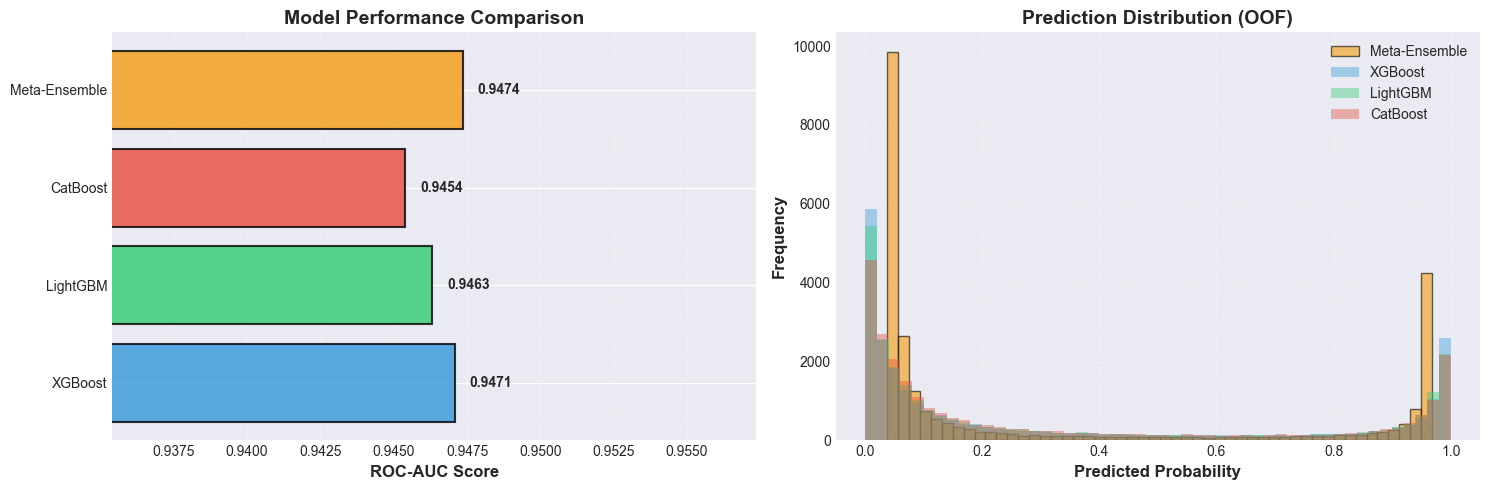

In [16]:
# Visualize model performance comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: CV AUC comparison
ax1 = axes[0]
models = ['XGBoost', 'LightGBM', 'CatBoost', 'Meta-Ensemble']
aucs = [cv_scores['xgb'], cv_scores['lgb'], cv_scores['cat'], meta_auc]
colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

bars = ax1.barh(models, aucs, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax1.set_xlabel('ROC-AUC Score', fontsize=12, fontweight='bold')
ax1.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax1.set_xlim(min(aucs) - 0.01, max(aucs) + 0.01)
ax1.grid(axis='x', alpha=0.3, linestyle='--')

# Add value labels
for i, (model, auc) in enumerate(zip(models, aucs)):
    ax1.text(auc + 0.0005, i, f'{auc:.4f}', va='center', fontsize=10, fontweight='bold')

# Plot 2: Prediction distribution comparison
ax2 = axes[1]
ax2.hist(meta_train_pred, bins=50, alpha=0.6, label='Meta-Ensemble', color='#f39c12', edgecolor='black')
ax2.hist(oof_predictions['xgb'], bins=50, alpha=0.4, label='XGBoost', color='#3498db')
ax2.hist(oof_predictions['lgb'], bins=50, alpha=0.4, label='LightGBM', color='#2ecc71')
ax2.hist(oof_predictions['cat'], bins=50, alpha=0.4, label='CatBoost', color='#e74c3c')
ax2.set_xlabel('Predicted Probability', fontsize=12, fontweight='bold')
ax2.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax2.set_title('Prediction Distribution (OOF)', fontsize=14, fontweight='bold')
ax2.legend(loc='upper right')
ax2.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

In [ ]:
# Visualize pseudo-labeling impact
if n_confident_total > 0:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    # Plot 1: Confidence distribution
    ax1 = axes[0]
    ax1.hist(meta_test_pred, bins=50, alpha=0.7, color='skyblue', edgecolor='black')
    ax1.axvline(HIGH_CONFIDENCE_THRESHOLD, color='red', linestyle='--', linewidth=2, 
                label=f'Bot threshold ({HIGH_CONFIDENCE_THRESHOLD})')
    ax1.axvline(LOW_CONFIDENCE_THRESHOLD, color='green', linestyle='--', linewidth=2, 
                label=f'Human threshold ({LOW_CONFIDENCE_THRESHOLD})')
    ax1.set_xlabel('Predicted Probability', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Frequency', fontsize=12, fontweight='bold')
    ax1.set_title('Test Set Prediction Confidence Distribution', fontsize=14, fontweight='bold')
    ax1.legend()
    ax1.grid(alpha=0.3, linestyle='--')
    
    # Plot 2: Pseudo-label distribution
    ax2 = axes[1]
    pseudo_label_counts = pd.Series(y_pseudo).value_counts().sort_index()
    colors_pie = ['#2ecc71', '#e74c3c']
    labels_pie = [f'Human\n({pseudo_label_counts[0]:,})', f'Bot\n({pseudo_label_counts[1]:,})']
    ax2.pie(pseudo_label_counts.values, labels=labels_pie, colors=colors_pie, autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
    ax2.set_title('Pseudo-Label Distribution', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n💡 Pseudo-labeling selected {n_confident_total:,} samples ({n_confident_total/len(test)*100:.1f}% of test set)")
else:
    print(f"\n⚠️ No confident predictions found with current thresholds")

## 9. Summary Report

In [ ]:
# Generate comprehensive summary report
print("="*70)
print("COMPREHENSIVE SUMMARY REPORT")
print("="*70)

print(f"\n📊 DATASET INFORMATION")
print(f"  Training samples: {len(train):,}")
print(f"  Test samples: {len(test):,}")
print(f"  Features (after preprocessing): {X_preprocessed.shape[1]}")

print(f"\n🎯 TARGET DISTRIBUTION")
for label, count in y_train.value_counts().sort_index().items():
    emoji = "🤖" if label == 1 else "👤"
    print(f"  {emoji} Class {label}: {count:,} ({count/len(y_train)*100:.1f}%)")

print(f"\n🔧 BASE MODELS")
print(f"  1. XGBoost")
print(f"     - CV AUC: {cv_scores['xgb']:.4f}")
print(f"     - Parameters: {len(xgb_params)} hyperparameters")
print(f"  2. LightGBM")
print(f"     - CV AUC: {cv_scores['lgb']:.4f}")
print(f"     - Parameters: {len(lgb_params)} hyperparameters")
print(f"  3. CatBoost")
print(f"     - CV AUC: {cv_scores['cat']:.4f}")
print(f"     - Parameters: {len(cat_params)} hyperparameters")

print(f"\n🎨 META-ENSEMBLE")
print(f"  Meta-models tested: {len(meta_results)}")
print(f"  Best meta-model: {best_meta_name}")
print(f"  Meta-features: {len(meta_train.columns)} (OOF predictions from base models)")
print(f"  Best CV AUC: {meta_auc:.4f}")
print(f"  Improvement over best base: {meta_auc - max(cv_scores.values()):+.4f}")

print(f"\n📊 All Meta-Models Tested:")
for name in results_df['Meta-Model'].values:
    auc = meta_results[name]['AUC']
    marker = "🏆" if name == best_meta_name else "  "
    print(f"  {marker} {name}: {auc:.4f}")

print(f"\n⚖️ MODEL WEIGHTS (Meta-Model Coefficients)")
for idx, row in coef_df.iterrows():
    print(f"  {row['Model']}: {row['Coefficient']:.4f}")

print(f"\n🔄 PSEUDO-LABELING")
print(f"  Confidence thresholds: >{HIGH_CONFIDENCE_THRESHOLD} (bot), <{LOW_CONFIDENCE_THRESHOLD} (human)")
print(f"  Pseudo-labeled samples: {n_confident_total:,} ({n_confident_total/len(test)*100:.1f}% of test)")
print(f"    - Bots: {n_confident_bots:,}")
print(f"    - Humans: {n_confident_humans:,}")
print(f"  Extended training set: {len(X_extended):,} (+{len(X_pseudo):,})")
print(f"  CV AUC with pseudo-labels: {cv_auc_extended:.4f}")
print(f"  Improvement: {improvement_pseudo:+.4f}")

print(f"\n🏆 FINAL SUBMISSION")
print(f"  Selected method: {final_method}")
print(f"  Expected AUC: {final_auc:.4f}")
print(f"  Submission file: {submission_path}")
print(f"  Prediction range: [{final_predictions.min():.4f}, {final_predictions.max():.4f}]")
print(f"  Prediction mean: {final_predictions.mean():.4f}")

print(f"\n💾 SAVED ARTIFACTS")
print(f"  ✓ OOF predictions: oof_predictions/")
print(f"  ✓ Meta-model: trained/meta_model.joblib")
print(f"  ✓ Submission: {submission_path}")
if FORCE_PSEUDO_LABELING:
    print(f"  ✓ Comparison submission: {meta_submission_path}")
    print(f"\n🧪 EXPERIMENT MODE")
    print(f"  You have 2 submissions to test on Kaggle:")
    print(f"    1. {submission_path} (pseudo-labeled)")
    print(f"    2. {meta_submission_path} (meta-ensemble)")

print(f"\n{'='*70}")
print(f"PIPELINE EXECUTION COMPLETE! 🎉")
print(f"{'='*70}")
print(f"\n✅ Ready for Kaggle submission!")
print(f"📈 Expected leaderboard position: Based on CV AUC of {final_auc:.4f}")
if FORCE_PSEUDO_LABELING:
    print(f"\n💡 TIP: Compare both submissions on Kaggle to see which works better!")

COMPREHENSIVE SUMMARY REPORT

📊 DATASET INFORMATION
  Training samples: 26,206
  Test samples: 11,232
  Features (after preprocessing): 33

🎯 TARGET DISTRIBUTION
  👤 Class 0: 17,423 (66.5%)
  🤖 Class 1: 8,783 (33.5%)

🔧 BASE MODELS
  1. XGBoost
     - CV AUC: 0.9471
     - Parameters: 12 hyperparameters
  2. LightGBM
     - CV AUC: 0.9463
     - Parameters: 12 hyperparameters
  3. CatBoost
     - CV AUC: 0.9454
     - Parameters: 10 hyperparameters

🎨 META-ENSEMBLE
  Meta-model: Logistic Regression
  Meta-features: 3 (OOF predictions from base models)
  CV AUC: 0.9474
  Improvement over best base: +0.0003

⚖️ MODEL WEIGHTS (Meta-Model Coefficients)
  cat_pred: 2.6187
  xgb_pred: 2.1370
  lgb_pred: 1.8504

🔄 PSEUDO-LABELING
  Confidence thresholds: >0.99 (bot), <0.01 (human)
  Pseudo-labeled samples: 0 (0.0% of test)
    - Bots: 0
    - Humans: 0
  Extended training set: 26,206 (+0)
  CV AUC with pseudo-labels: 0.9471
  Improvement: +0.0000

🏆 FINAL SUBMISSION
  Selected method: Meta-En

---

## 📝 Notes and Usage Instructions

### How to Use This Notebook

1. **Prerequisites:**
   - Ensure all Optuna studies are available in `trained/` directory
   - If studies are missing, the notebook will use default parameters
   - GPU acceleration is optional but recommended (set `tree_method='gpu_hist'` for XGBoost, `device='gpu'` for LightGBM/CatBoost)

2. **Customization:**
   - **Force Pseudo-Labeling:** Set `FORCE_PSEUDO_LABELING = True` in Configuration cell to always use pseudo-labeled predictions (useful for A/B testing on Kaggle)
   - Adjust confidence thresholds for pseudo-labeling (default: 0.99 for bots, 0.01 for humans)
   - Modify cross-validation folds (`N_SPLITS`, default: 5)
   - Change meta-model (current: Logistic Regression, alternatives: Ridge, XGBoost, etc.)

3. **Testing Pseudo-Labeling on Kaggle:**
   - Run notebook with `FORCE_PSEUDO_LABELING = False` → generates `meta_ensemble.csv` (best method selected automatically)
   - Run notebook with `FORCE_PSEUDO_LABELING = True` → generates:
     - `meta_ensemble_pseudo_forced.csv` (pseudo-labeled predictions)
     - `meta_ensemble_comparison.csv` (meta-ensemble predictions for comparison)
   - Submit both to Kaggle to see which performs better on the leaderboard!

3. **Performance Tips:**
   - Use GPU acceleration for faster training (20-30 minutes vs 45-60 minutes on CPU)
   - Reduce `N_SPLITS` to 3 for faster experimentation
   - Lower pseudo-label thresholds (e.g., 0.95/0.05) to include more samples

4. **Expected Runtime:**
   - Full pipeline (CPU): ~60-90 minutes
   - Full pipeline (GPU): ~30-45 minutes
   - Each base model: ~15-20 minutes (CPU), ~5-10 minutes (GPU)

5. **Output Files:**
   - `oof_predictions/`: OOF predictions for each base model
   - `trained/meta_model.joblib`: Trained meta-ensemble model
   - `../submissions/meta_ensemble.csv`: Final submission file

### Key Features

✅ **5-fold Stratified Cross-Validation** for robust performance estimation  
✅ **Optuna-tuned hyperparameters** for optimal base model performance  
✅ **Meta-ensembling** to combine diverse model predictions  
✅ **Pseudo-labeling** for semi-supervised learning  
✅ **Automatic best model selection** based on CV performance  
✅ **Comprehensive visualization** of results and model behavior  
✅ **GPU support** for faster training (optional)

### Troubleshooting

- **Memory Error:** Reduce `N_SPLITS` or process data in smaller batches
- **Slow Training:** Enable GPU acceleration or reduce number of base models
- **Low Performance:** Check feature engineering, try different meta-model (e.g., XGBoost)
- **Feature Mismatch:** Ensure train/test preprocessing is consistent

### Next Steps

1. **Ensemble with NLP features:** Add XGBoost+NLP as a 4th base model
2. **Try different meta-models:** Test Ridge, Lasso, or gradient boosting as meta-learner
3. **Tune pseudo-label thresholds:** Experiment with different confidence levels
4. **Stack more models:** Add Random Forest, Neural Network, etc.
5. **Feature selection:** Use SHAP or feature importance to reduce dimensionality